# Best Beloved: Autoregressive Text Generation on Kipling's Animal Tales

**Aditya Bhansali** · Registration number 230953272  
Foundations of Generative AI (ICT4403), Assignment 2

This notebook is the written record of the experiment. Training is implemented in `run_experiment.py` and the modules under `src/`. The cells below load the saved run, so they do not retrain the four models. Reproduce the run with `python run_experiment.py` (about four minutes on an Apple M2).


## 1. Objective

Predict the next word from a 20-token window, then generate text by sampling that prediction and sliding the window. Simple RNN, bidirectional RNN, LSTM, and GRU models are trained with the same data, loss, batch size, learning rate, dropout, and epoch budget.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import torch
from IPython.display import Image, Markdown, display

from src.config import ARCHITECTURES, ARCH_LABELS
from src.models import NextWordModel

root = Path.cwd()
metrics = json.loads((root / "results" / "metrics.json").read_text())
stats = metrics["dataset"]
print(metrics["system_title"])
print("device:", metrics["device"], "| seed:", metrics["seed"])
print("vocabulary:", stats["vocab_size"], "| train windows:", stats["train_windows"], "| val windows:", stats["val_windows"])


Best Beloved: Autoregressive Text Generation on Kipling's Animal Tales
device: mps | seed: 42
vocabulary: 4551 | train windows: 70211 | val windows: 12383


## 2. Dataset

The corpus is three public-domain Kipling books with one narrative style: animal dialogue, stock phrases, and a recurring cast. That repetition is useful for a small word-level model, and the collection is a less usual choice than Shakespeare or a news crawl.

Sources:

- *The Jungle Book* (1894) — https://www.gutenberg.org/ebooks/236
- *The Second Jungle Book* (1895) — https://www.gutenberg.org/ebooks/1937
- *Just So Stories* (1902) — https://www.gutenberg.org/ebooks/2781

Preprocessing strips the Gutenberg header and footer, lowercases the text, and tokenises words plus `, . ! ? ; :`. Each book is split 85/15 in order, so a window cannot appear in both sets. The vocabulary is fit on the training tokens only; words seen once become `<unk>`. Each example is 20 context tokens and the single following token, with stride 2.


In [2]:
print(f"{'Book':<28} {'Year':>6} {'Tokens':>10}")
for book in stats["books"]:
    print(f"{book['title']:<28} {book['year']:>6} {book['tokens']:>10,}")
print()
rows = [
    ("Total tokens", stats["total_tokens"]),
    ("Training tokens", stats["train_tokens"]),
    ("Validation tokens", stats["val_tokens"]),
    ("Vocabulary", stats["vocab_size"]),
    ("Type-token ratio (train)", stats["type_token_ratio_train"]),
    ("Mean sentence length", stats["mean_sentence_length_tokens"]),
    ("Validation <unk> rate", stats["val_target_unk_rate"]),
]
for name, value in rows:
    print(f"{name:<28} {value}")
print("\nMost frequent training tokens:")
print(", ".join(f"{token} ({count})" for token, count in stats["most_frequent_train_tokens"][:8]))


Book                           Year     Tokens
The Jungle Book                1894     58,341
The Second Jungle Book         1895     73,647
Just So Stories                1902     33,240

Total tokens                 165228
Training tokens              140442
Validation tokens            24786
Vocabulary                   4551
Type-token ratio (train)     0.0612
Mean sentence length         19.03
Validation <unk> rate        0.0647

Most frequent training tokens:
, (9431), the (9221), and (5753), . (5671), of (2945), to (2533), a (2525), he (2250)


## 3. Models and shared setup

`NextWordModel` in `src/models.py` shares the embedding (128), dropout (0.2), and output layer. The bidirectional RNN uses 128 units in each direction so the concatenated state is 256, matching the other models. It encodes the context window only. The target word is never inside that window.

Training uses Adam at learning rate 0.001, batch size 256, gradient clipping at 1.0, and 10 epochs. The checkpoint with the lowest validation loss is the one used for sampling.


In [3]:
device = torch.device("cpu")
print(f"{'Model':<20} {'Parameters':>12}")
for arch in ARCHITECTURES:
    model = NextWordModel(stats["vocab_size"], arch)
    print(f"{ARCH_LABELS[arch]:<20} {model.parameter_count():>12,}")
    logged = metrics["models"][arch]["parameters"]
    assert model.parameter_count() == logged

hp = metrics["hyperparameters"]
print()
for key in ["seq_len", "stride", "embed_dim", "hidden_dim", "dropout", "batch_size", "learning_rate", "epochs"]:
    print(f"{key:<16} {hp[key]}")


Model                  Parameters
Simple RNN              1,850,951
Bidirectional RNN       1,818,183
LSTM                    2,147,399
GRU                     2,048,583

seq_len          20
stride           2
embed_dim        128
hidden_dim       256
dropout          0.2
batch_size       256
learning_rate    0.001
epochs           10


## 4. Quantitative comparison

Perplexity is `exp(cross-entropy)`. A uniform guess over this vocabulary would score 4,551, so every model has learned the corpus. Validation accuracy stays near 17.5% for all four because many next words are plausible; perplexity is the score that separates them.

Dashed curves are training loss. Solid curves are validation. Training loss keeps falling after validation loss has turned up, so all four overfit, and generation uses the best validation epoch rather than epoch 10.


Model              Epoch  Val loss  Val ppl  Val acc  Seconds
-------------------------------------------------------------
Simple RNN             5     4.983    145.9    17.4%     46.7
Bidirectional RNN      5     4.965    143.3    17.1%     57.2
LSTM                   8     4.916    136.4    17.5%     59.2
GRU                    5     4.884    132.2    17.5%     57.5


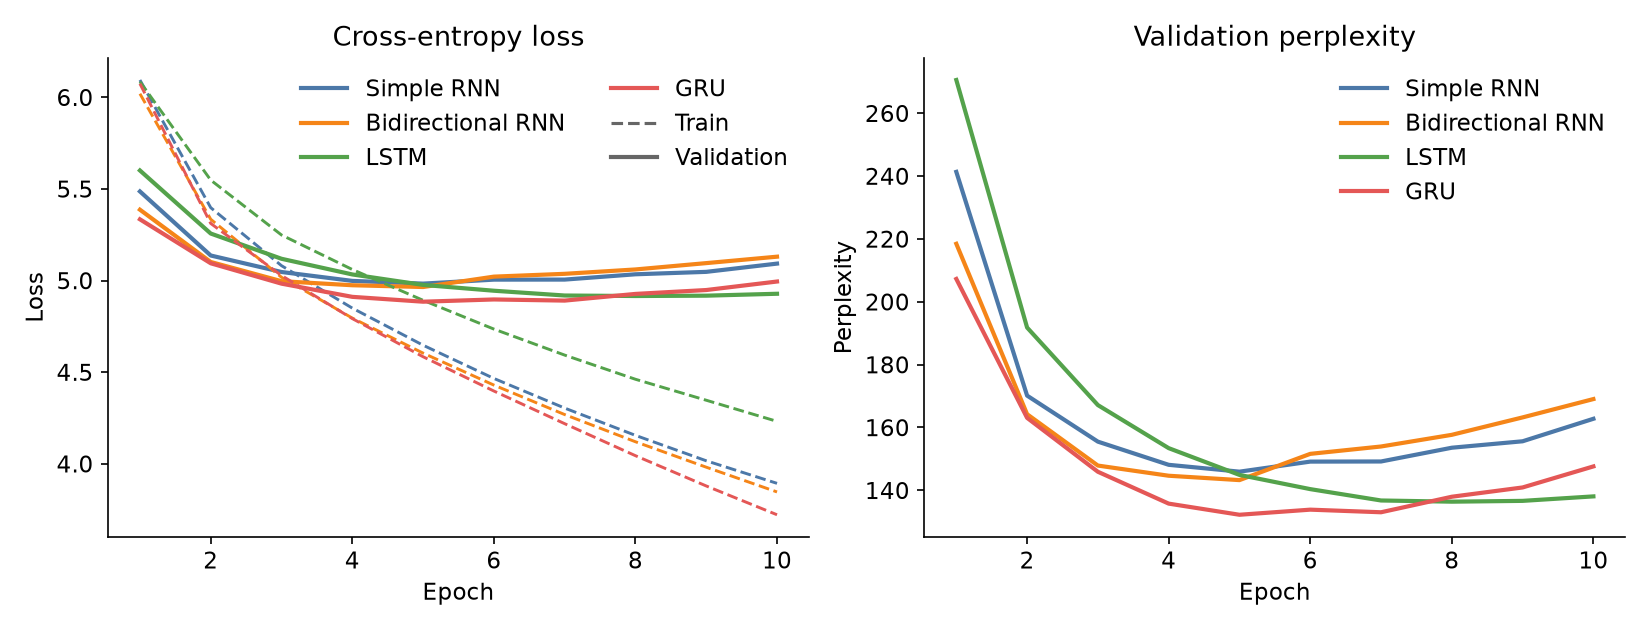

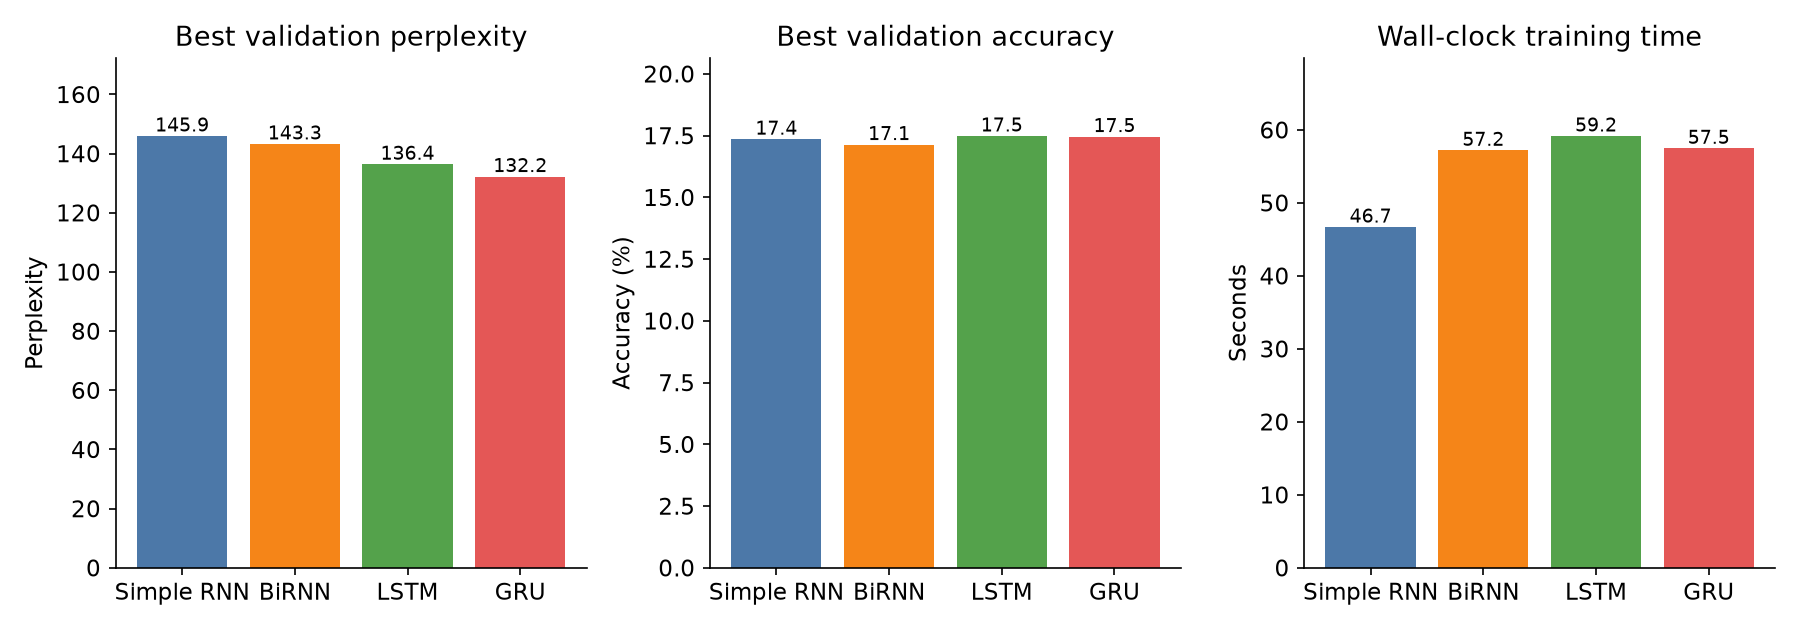

In [4]:
header = f"{'Model':<18} {'Epoch':>5} {'Val loss':>9} {'Val ppl':>8} {'Val acc':>8} {'Seconds':>8}"
print(header)
print("-" * len(header))
for arch in ARCHITECTURES:
    row = metrics["models"][arch]
    print(
        f"{ARCH_LABELS[arch]:<18} {row['best_epoch']:>5} "
        f"{row['best_val_loss']:>9.3f} {row['best_val_perplexity']:>8.1f} "
        f"{100 * row['best_val_accuracy']:>7.1f}% {row['train_seconds']:>8.1f}"
    )

for name in ["training_curves.png", "model_comparison.png"]:
    display(Image(filename=str(root / "results" / "plots" / name)))


### Reading the numbers

The GRU has the lowest validation perplexity, 132.2, at epoch 5 and 57.5 seconds. The LSTM is second at 136.4, needing epoch 8 and 59.2 seconds, and it is the largest network. The bidirectional RNN gains 2.7 perplexity points on the simple RNN (143.3 against 145.9) and gives up a little accuracy. A backward pass over 20 tokens is a small improvement. The simple RNN is the fastest run, 46.7 seconds, and the weakest language model.

LSTM validation accuracy at the chosen checkpoint is 17.48%, and GRU accuracy is 17.46%. Those are tied for this metric. The GRU ranks first once the full predictive distribution is scored.


## 5. Temperature

Continuations are 70 tokens from three shared seeds, at temperatures 0.5, 1.0, and 1.5. The `<unk>` class is masked while sampling so the printed text is made of real words. The same mask is used for every model. Loss, perplexity, and accuracy above still treat `<unk>` as a class.

Distinct-2 is the fraction of generated bigrams that are unique. It rises with temperature for every model. Immediate word-for-word repetition stays near zero; the repetition that matters is the repeated phrase (`of the jungle`, `and the little`).


Model                 T=0.5    T=1.0    T=1.5
Simple RNN            0.773    0.990    1.000
Bidirectional RNN     0.734    0.966    1.000
LSTM                  0.739    0.995    1.000
GRU                   0.739    0.971    1.000


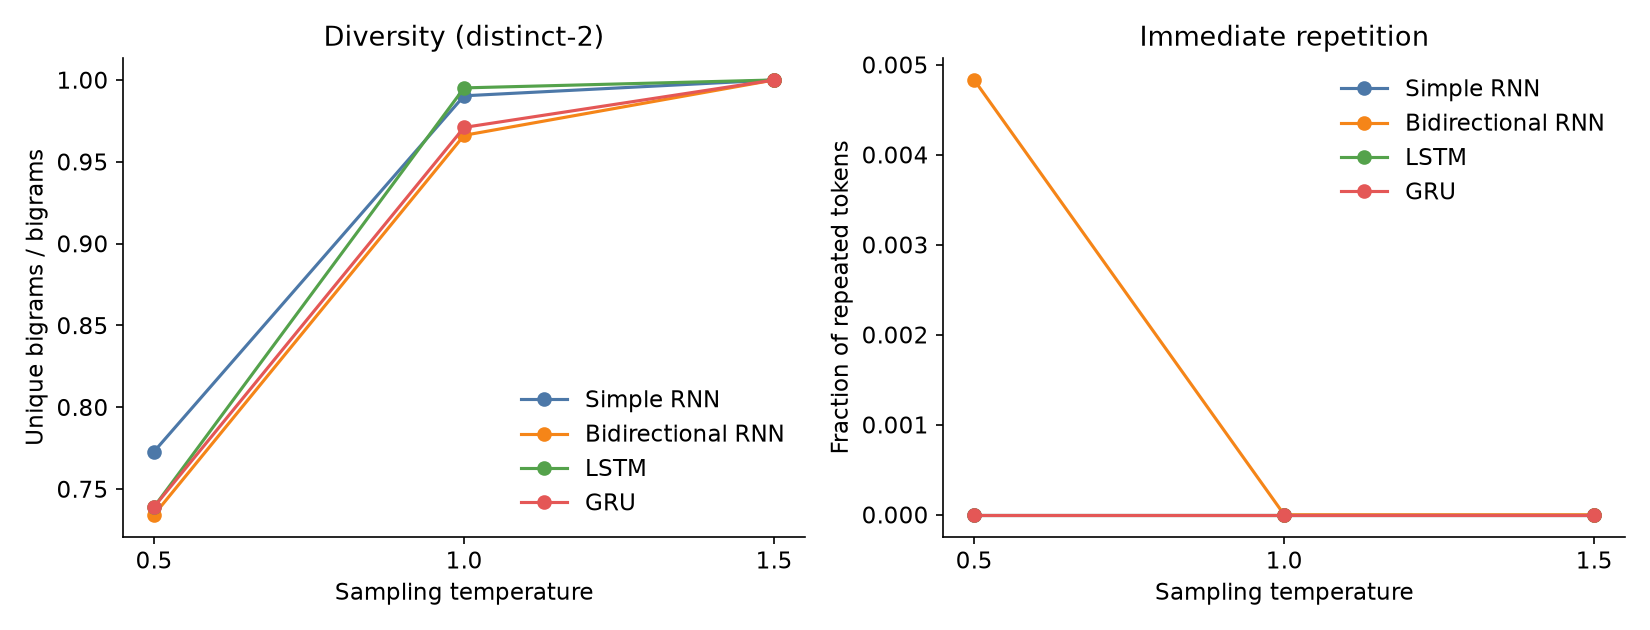


Temperature 1.0, seed: in the sea once upon a time

Simple RNN
[in the sea once upon a time] . o jungle one, said the waked, but i have fed out of the pack in the gale nose. all, bare white panther loud and wagai feet it, said mowgli, and zebra at her is. by the dog raced the baby into a long shoot on the late to it. then the sense ants, lash, many little, so when

Bidirectional RNN
[in the sea once upon a time] when the crash never swung. shouted they is thrown to a half edge over the old could put of those stones, but here? said me, said, as the boy, too, said it as it will not no taffy, give their man, rising out any than days, and a dry notion with their soft snap by kotick, and good have

LSTM
[in the sea once upon a time] ? said bagheera. i am tall husband! catching he is hold. if we shall trail. which is like the hunters yellow brother? i hate to trail! and he had would be long forward man of the purr. so on the first as the jungle gives me work. what was a i, fat wolf. yes, sa

In [5]:
temps = ["0.5", "1.0", "1.5"]
print(f"{'Model':<18} " + " ".join(f"{'T=' + temp:>8}" for temp in temps))
for arch in ARCHITECTURES:
    values = [metrics["temperature_summary"][arch][temp]["distinct_2"] for temp in temps]
    print(f"{ARCH_LABELS[arch]:<18} " + " ".join(f"{value:8.3f}" for value in values))

display(Image(filename=str(root / "results" / "plots" / "temperature_effects.png")))

print("\nTemperature 1.0, seed: in the sea once upon a time\n")
for sample in metrics["samples"]:
    if sample["temperature"] == 1.0 and sample["seed"].startswith("in the sea"):
        print(ARCH_LABELS[sample["architecture"]])
        print(sample["text"])
        print()


### What the samples do

At temperature 0.5 the prose is the most clause-like and the most formulaic. The bidirectional RNN repeats frames (`the little time, and the little time`). The simple RNN stays grammatical and then mixes casts: the eldest magician, council rocks, and "the sun is the zebra" in one continuation. The GRU keeps Kipling's animals in shorter loops (`the mugger of the tigers`, `the bhagat of the jungle`). The LSTM often has the cleanest local grammar (`he was hungry, as he was a man, and he could not help him`) with agreement still breaking (`who were very good`).

At temperature 1.0 the phrase loops recede and dialogue tags from the books show up (`said bagheera`, `said kaa`, `said stickly-prickly`). The GRU is slightly less diverse than the LSTM at this temperature because its distribution is sharper. Neither model holds a plot together.

At temperature 1.5 distinct-2 is 1.0 for every model. Names from the books remain, and syntactic roles disappear. That setting measures diversity; it is a poor setting for reading.

Context has a shared limit. The sea seed turns into jungle prose within a sentence for every model, and the Law of the Jungle seed is continued as prose rather than verse. The 20-token window learns the sound of the books. It does not keep a scene.


## 6. Conclusion

The GRU is the most effective model for this dataset. It has the lowest validation perplexity (132.2), the same next-word accuracy as the LSTM (17.5%), and a training time level with the bidirectional RNN. Temperature 1.0 is the sampling setting that balances coherence and diversity. Temperature 0.5 is more grammatical and more repetitive. Temperature 1.5 is diverse and stops reading as prose.

The LSTM is the runner-up: a few of its lines sound the most like speech, at a higher parameter count, a longer run, and a worse perplexity. The bidirectional RNN's second direction is a small gain over the simple RNN. The simple RNN is the cheapest model and the weakest language model.

The full sample set is `results/generated_samples.md`. The same discussion, with the quantitative table, is in `README.md`.
